In [25]:
# Cell 2 - Imports
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [31]:
# Cell 4 - Fetch GSE43346 from GEO
import urllib.request
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE43nnn/GSE43346/soft/GSE43346_family.soft.gz"
urllib.request.urlretrieve(url, './data/raw/GSE43346_family.soft.gz')
GSE43346 = GEOparse.get_GEO(filepath='./data/raw/GSE43346_family.soft.gz')

06-Mar-2026 08:48:25 INFO GEOparse - Parsing ./data/raw/GSE43346_family.soft.gz: 
06-Mar-2026 08:48:25 DEBUG GEOparse - DATABASE: GeoMiame
06-Mar-2026 08:48:25 DEBUG GEOparse - SERIES: GSE43346
06-Mar-2026 08:48:25 DEBUG GEOparse - PLATFORM: GPL96
06-Mar-2026 08:48:26 DEBUG GEOparse - PLATFORM: GPL97
06-Mar-2026 08:48:26 DEBUG GEOparse - PLATFORM: GPL570
D:\Anaconda\Lib\site-packages\GEOparse\GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060726
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060727
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060728
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060729
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060730
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060731
06-Mar-2026 08:48:28 DEBUG GEOparse - SAMPLE: GSM1060732
06-Mar-2026 08:48:28 DEBUG G

In [33]:
print(GSE43346.metadata)

{'title': ['Gene repression with H3K27me3 modification in human small cell lung cancer'], 'geo_accession': ['GSE43346'], 'status': ['Public on Jun 12 2013'], 'submission_date': ['Jan 08 2013'], 'last_update_date': ['Mar 25 2019'], 'pubmed_id': ['23714854'], 'summary': ['Small cell lung cancer (SCLC) is a subtype of lung cancer with poor prognosis due to early dissemination and rapid growth. We here analyze gene expression profile of 23 clinical SCLC samples. EZH2 was found to be highly expressed in SCLC samples compared to 42 normal tissues including the normal lung, and other PRC2 members, SUZ12 and EED, were also highly expressed in SCLC. To obtain target genes of PRC2 in SCLC, H3K27me3 mark was mapped in three SCLC cell lines, Lu130, H209 and DMS53, and compared to normal small airway epithelial cells (SAEC). Whereas H3K27me3(+) genes in SAEC were significantly overlapped with PRC-target genes in ES cells (P=1.7x10-31), genes with H3K27me3 in SCLC cell lines but not in SAEC were not

In [35]:
# Cell 6 - Inspect samples
for gsm_name, gsm in GSE43346.gsms.items():
    print(gsm_name, gsm.metadata['title'])

GSM1060726 ['Whole_Brain']
GSM1060727 ['Cerebral_cortex']
GSM1060728 ['Pons']
GSM1060729 ['Hippocampus']
GSM1060730 ['Diencephalon']
GSM1060731 ['Thalamus']
GSM1060732 ['Cerebellum']
GSM1060733 ['Skeletal_muscle']
GSM1060734 ['Heart']
GSM1060735 ['Skin']
GSM1060736 ['Tongue']
GSM1060737 ['Esophagus']
GSM1060738 ['Stomach']
GSM1060739 ['Small_intestine']
GSM1060740 ['Colon']
GSM1060741 ['Pancreas']
GSM1060742 ['Liver']
GSM1060743 ['Gallbladder']
GSM1060744 ['Kidney']
GSM1060745 ['Adrenal_gland']
GSM1060746 ['Bladder']
GSM1060747 ['Salivary_gland']
GSM1060748 ['Tonsil']
GSM1060749 ['Thyroid']
GSM1060750 ['Thymus']
GSM1060751 ['Trachea']
GSM1060752 ['Lung']
GSM1060753 ['Spleen']
GSM1060754 ['Adipose']
GSM1060755 ['Lymph_node']
GSM1060756 ['Artery']
GSM1060757 ['Vein']
GSM1060758 ['Bone_marrow']
GSM1060759 ['Peripheral_blood_cells']
GSM1060760 ['Monocyte']
GSM1060761 ['Macrophage']
GSM1060762 ['Testis']
GSM1060763 ['Prostate']
GSM1060764 ['Seminal_vesicle']
GSM1060765 ['Breast']
GSM1060766

In [37]:
# Cell 7 - Inspect a single sample to understand data structure
sample = list(GSE43346.gsms.values())[0]
print(sample.table.head())
print(sample.table.shape)

           ID_REF  VALUE
0  AFFX-BioB-5_at   17.4
1  AFFX-BioB-M_at    5.0
2  AFFX-BioB-3_at    1.7
3  AFFX-BioC-5_at  583.8
4  AFFX-BioC-3_at  606.4
(54675, 2)


In [41]:
# Cell 8 - Build expression matrix for SCLC and Normal samples onl
samples_of_interest = {}

for gsm_id, gsm in GSE43346.gsms.items():
    title = gsm.metadata['title'][0]
    if 'SCLC' in title:
        samples_of_interest[gsm_id] = 'SCLC'
    elif 'Lung' in title:
        samples_of_interest[gsm_id] = 'Normal'

print('Selected samples:')
for gsm_id, group in samples_of_interest.items():
    print(f' {gsm_id}: {group}')

print(f'\nTotal: {len(samples_of_interest)}samples')

Selected samples:
 GSM1060752: Normal
 GSM1060768: SCLC
 GSM1060769: SCLC
 GSM1060770: SCLC
 GSM1060771: SCLC
 GSM1060772: SCLC
 GSM1060773: SCLC
 GSM1060774: SCLC
 GSM1060775: SCLC
 GSM1060776: SCLC
 GSM1060777: SCLC
 GSM1060778: SCLC
 GSM1060779: SCLC
 GSM1060780: SCLC
 GSM1060781: SCLC
 GSM1060782: SCLC
 GSM1060783: SCLC
 GSM1060784: SCLC
 GSM1060785: SCLC
 GSM1060786: SCLC
 GSM1060787: SCLC
 GSM1060788: SCLC
 GSM1060789: SCLC
 GSM1060790: SCLC

Total: 24samples


In [45]:
# Check platform for each selected sample
for gsm_id, group in samples_of_interest.items():
    platform_id = GSE43346.gsms[gsm_id].metadata['platform_id'][0]
    print(f"{gsm_id} ({group}): {platform_id}")

GSM1060752 (Normal): GPL570
GSM1060768 (SCLC): GPL570
GSM1060769 (SCLC): GPL570
GSM1060770 (SCLC): GPL570
GSM1060771 (SCLC): GPL570
GSM1060772 (SCLC): GPL570
GSM1060773 (SCLC): GPL570
GSM1060774 (SCLC): GPL570
GSM1060775 (SCLC): GPL570
GSM1060776 (SCLC): GPL570
GSM1060777 (SCLC): GPL570
GSM1060778 (SCLC): GPL570
GSM1060779 (SCLC): GPL570
GSM1060780 (SCLC): GPL570
GSM1060781 (SCLC): GPL570
GSM1060782 (SCLC): GPL570
GSM1060783 (SCLC): GPL570
GSM1060784 (SCLC): GPL570
GSM1060785 (SCLC): GPL570
GSM1060786 (SCLC): GPL570
GSM1060787 (SCLC): GPL570
GSM1060788 (SCLC): GPL570
GSM1060789 (SCLC): GPL570
GSM1060790 (SCLC): GPL570


In [57]:
for platform_id, platform in GSE43346.gpls.items():
    print(f"{platform_id}: {platform.table.shape[0]} probes")

GPL96: 22283 probes
GPL97: 22645 probes
GPL570: 54675 probes


In [55]:
# Cell 9 - Inspect platform annotation
platform = platform = GSE43346.gpls['GPL570']
print(platform.table.head())
print(platform.table.columns.tolist())

          ID  GB_ACC SPOT_ID Species Scientific Name Annotation Date  \
0  1007_s_at  U48705     NaN            Homo sapiens     Oct 6, 2014   
1    1053_at  M87338     NaN            Homo sapiens     Oct 6, 2014   
2     117_at  X51757     NaN            Homo sapiens     Oct 6, 2014   
3     121_at  X69699     NaN            Homo sapiens     Oct 6, 2014   
4  1255_g_at  L36861     NaN            Homo sapiens     Oct 6, 2014   

       Sequence Type                  Sequence Source  \
0  Exemplar sequence  Affymetrix Proprietary Database   
1  Exemplar sequence                          GenBank   
2  Exemplar sequence  Affymetrix Proprietary Database   
3  Exemplar sequence                          GenBank   
4  Exemplar sequence  Affymetrix Proprietary Database   

                                  Target Description Representative Public ID  \
0  U48705 /FEATURE=mRNA /DEFINITION=HSU48705 Huma...                   U48705   
1  M87338 /FEATURE= /DEFINITION=HUMA1SBU Human re...          

In [61]:
# Cell 10 - Build annotated expression matrix

# Step 1 - Build raw matrix
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE43346.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id #Names that column after the GSM ID so we know which sample it belongs to
    expr_matrix = pd.concat([expr_matrix, df], axis=1) #axis=1 means add as a column, not a row

# Step 2 - Get platform annotation
annotation = platform.table[['ID','Gene Symbol']]

# Step 3 - Remove unannotated probes
annotation = annotation[annotation['Gene Symbol'].notna()]
annotation = annotation[annotation['Gene Symbol']!= '']

# Step 4 - Remove multi-gene probe
annotation = annotation[~annotation['Gene Symbol'].str.contains('///')]

# Step 5 - Merge expression matrix with annotation
expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(annotation, left_index=True, right_on='ID')
expr_matrix = expr_matrix.set_index('Gene Symbol').drop(columns='ID')

# Step 6 - Colllaspe duplicate by mean
expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

expr_matrix = np.log2(expr_matrix + 1)

print(expr_matrix.shape)
print(expr_matrix.head())

(21655, 24)
             GSM1060752  GSM1060768  GSM1060769  GSM1060770  GSM1060771  \
Gene Symbol                                                               
A1BG           4.472488    5.197708    5.794416    5.825277    4.837943   
A1BG-AS1       1.678072    2.035624    4.078951    2.807355    1.536053   
A1CF           2.608809    4.993221    2.954196    3.972693    4.371559   
A2M           12.076983    9.934575    9.248283    8.608440    8.586465   
A2M-AS1        5.247928    2.232661    4.733354    5.125155    5.862947   

             GSM1060772  GSM1060773  GSM1060774  GSM1060775  GSM1060776  ...  \
Gene Symbol                                                              ...   
A1BG           5.452859    5.736064    4.078951    5.680887    5.137504  ...   
A1BG-AS1       2.292782    2.292782    1.321928    2.378512    2.000000  ...   
A1CF           4.686501    4.542258    4.578939    4.703211    4.388878  ...   
A2M            8.584399    8.397889    8.883560    9.314243   

In [63]:
# Cell 11 - Check for NA values
print(f'Total NA values: {expr_matrix.isna().sum().sum()}')
print(f'\nNa value per sample:')
print(expr_matrix.isna().sum())

Total NA values: 0

Na value per sample:
GSM1060752    0
GSM1060768    0
GSM1060769    0
GSM1060770    0
GSM1060771    0
GSM1060772    0
GSM1060773    0
GSM1060774    0
GSM1060775    0
GSM1060776    0
GSM1060777    0
GSM1060778    0
GSM1060779    0
GSM1060780    0
GSM1060781    0
GSM1060782    0
GSM1060783    0
GSM1060784    0
GSM1060785    0
GSM1060786    0
GSM1060787    0
GSM1060788    0
GSM1060789    0
GSM1060790    0
dtype: int64


In [65]:
expr_matrix.to_csv('./data/processed/GSE43346_expression_matrix.csv')
print('Expression matirx saved!')

Expression matirx saved!


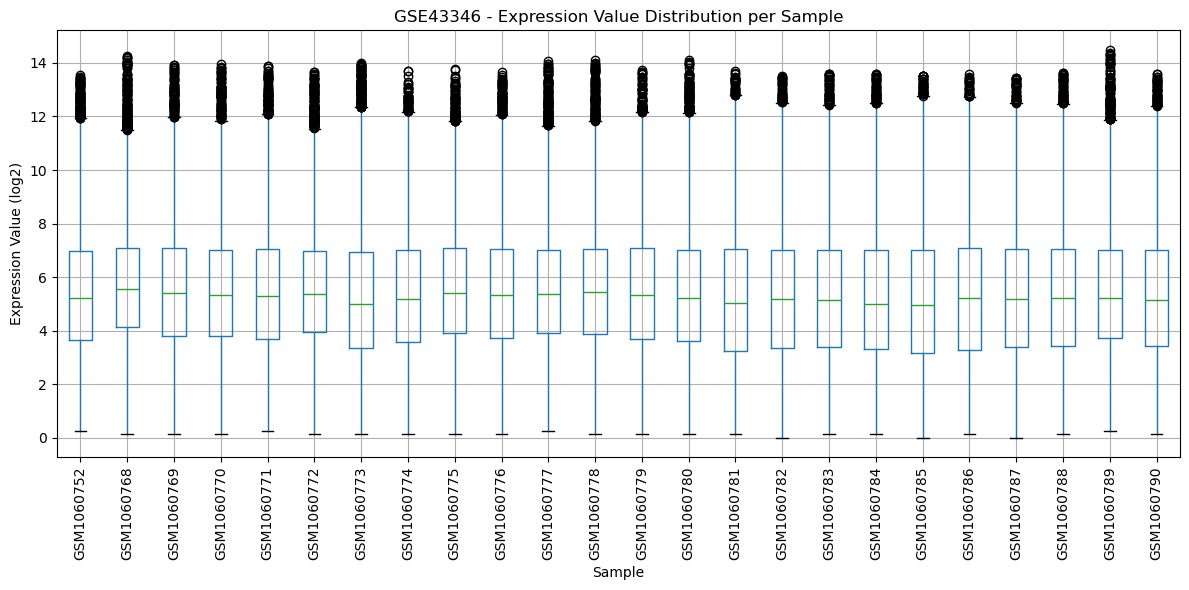

In [67]:
# Cell 13 - Sample distribution boxplot
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE43346 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE43346_boxplot.png', dpi=300)
plt.show()

In [69]:
# Cell 14 - Create metadata dataframe
metadata = pd.DataFrame({
    'sample_id' : list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE43346_metadata.csv')
print(metadata)

             group
sample_id         
GSM1060752  Normal
GSM1060768    SCLC
GSM1060769    SCLC
GSM1060770    SCLC
GSM1060771    SCLC
GSM1060772    SCLC
GSM1060773    SCLC
GSM1060774    SCLC
GSM1060775    SCLC
GSM1060776    SCLC
GSM1060777    SCLC
GSM1060778    SCLC
GSM1060779    SCLC
GSM1060780    SCLC
GSM1060781    SCLC
GSM1060782    SCLC
GSM1060783    SCLC
GSM1060784    SCLC
GSM1060785    SCLC
GSM1060786    SCLC
GSM1060787    SCLC
GSM1060788    SCLC
GSM1060789    SCLC
GSM1060790    SCLC


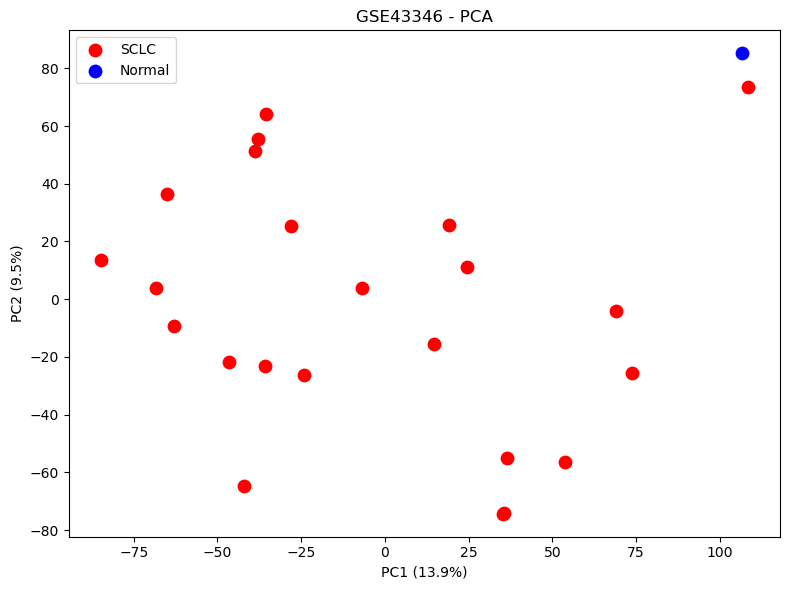

In [71]:
# Cell 15 - PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the data
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

# Plot
plt.figure(figsize=(8, 6))
colors = {'SCLC': 'red', 'Normal': 'blue'}
for group in ['SCLC', 'Normal']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE43346 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE43346_PCA.png', dpi=300)
plt.show()